Jeremy Barton<br>
Term Project: Milestone 1<br>
DSC550-T302<br>
Spring 2026

# WigglNet: Data Mining and Brokerage Service for E-Commerce Niche Market Sellers and Small to Mid-size Product Manufacturers

### Business Question

Small e-commerce sellers and product manufacturers struggle to understand what is popular, why and what will be popular in the future. This data could be retrieved by a search engine or AI, but there is more value in using advanced models specially trained to identify people, organizations or entities related to a specific product category to discover these insights rather than a Large Language Model trained on everything, that happens to have picked up data related to a particular target market.

The question being asked in this business problem is <i>"Can we predict the sentiment of keywords and entities related to a certain product niche based on a classification model trained on hundreds of web articles related to that category within a certain time frame?</i>"

A great way to examine this, for the article data at least, is to target the `sentiment` column of ARTICLE_ENTITY_SENTIMENT table, which is the variable tied to the mood of a keyword or entity. It is broken down into three classes: <b>positive, neutral and negative</b>. This is one of the most useful variables to analyze becuase it tells a client how to make decisions about these entities.

### Exploring the Data

MariaDB is the database system used for development purposes.

In [29]:
# Imports and Processing
import sys
sys.path.insert(0, '/home/jeremy/Documents/GitHub/wigglnet')

import mariadb
import pandas as pd
from app.shared_utils.db_utils import get_db_config

# Get database configuration from .env file
config = get_db_config()

# Connect to DB
try:
    conn = mariadb.connect(
        host=config['host'],
        user=config['user'],
        password=config['password'],
        database=config['database'],
        port=config['port']
    )
    print("Successfully connected to MariaDB database")
except mariadb.Error as e:
    print(f"Error connecting to MariaDB Platform: {e}")
    sys.exit(1)

# Get the cursor
cur = conn.cursor()

Successfully connected to MariaDB database


The SQL query is pulling back combined article, keyword, entity and sentiment information by joining to four other tables on either ARTICLE_ID or KEYWORD_ID. Using multiple tables with a JOIN, an overview of the joined insight data is stored in a dataframe. Because this is time series data, the query can ignore all rows where PUBLISHED_DATE is NULL.

The query includes the CONFIDENCE field from ARTICLE_ENTITY_SENTIMENT, which indicates the RoBERTa model's confidence level (0-1) in the sentiment classification for each entity.

In [30]:
# SQL Query to retrieve article data with keywords, entities, and sentiment
query = """
    SELECT
        a.ARTICLE_ID,
        a.TITLE,
        a.PUBLISHED_DATE,
        k.KEYWORD_TEXT,
        e.ENTITY_TEXT,
        e.ENTITY_TYPE,
        aes.SENTIMENT,
        aes.CONFIDENCE,
        aes.MENTIONS
    FROM WEBDATA.ARTICLES a
    LEFT JOIN WEBDATA.ARTICLE_KEYWORDS ak ON a.ARTICLE_ID = ak.ARTICLE_ID
    LEFT JOIN WEBDATA.KEYWORDS k ON ak.KEYWORD_ID = k.KEYWORD_ID
    LEFT JOIN WEBDATA.ARTICLE_ENTITY_SENTIMENT aes ON a.ARTICLE_ID = aes.ARTICLE_ID
    LEFT JOIN WEBDATA.ENTITIES e ON aes.ENTITY_ID = e.ENTITY_ID
    WHERE PUBLISHED_DATE IS NOT NULL
    AND published_date BETWEEN CURRENT_DATE - INTERVAL 1 YEAR AND CURRENT_DATE;
"""

# Execute query and load results into a DataFrame
df = pd.read_sql(query, conn)

/tmp/ipykernel_13687/2886141593.py:23: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


In [31]:
# Display basic info about the dataset
print(f"Dataset shape: {df.shape}")
print(f"\nColumn names: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (13922, 9)

Column names: ['ARTICLE_ID', 'TITLE', 'PUBLISHED_DATE', 'KEYWORD_TEXT', 'ENTITY_TEXT', 'ENTITY_TYPE', 'SENTIMENT', 'CONFIDENCE', 'MENTIONS']

First few rows:


,ARTICLE_ID,TITLE,PUBLISHED_DATE,KEYWORD_TEXT,ENTITY_TEXT,ENTITY_TYPE,SENTIMENT,CONFIDENCE,MENTIONS
0,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Next,ORG,neutral,0.725,3
1,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,House,ORG,positive,0.676,3
2,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Eisenhart,PERSON,neutral,0.841,2
3,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Alexandra Gater,PERSON,positive,0.952,2
4,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Ikea,NORP,neutral,0.720,2


How many articles are in this dataset?

In [32]:
total_articles = df["ARTICLE_ID"].nunique()
print(f"There are {total_articles} articles in this dataset.")

There are 95 articles in this dataset.


<b>If there are only 132 articles, why are there 19,637 rows?<b>

This dataset includes information on metadata about keywords and enitities in an article, not just a list of each article.

Every keyword has an entity text, type, sentiment and number of mentions.

What are the max and min published dates?

In [33]:
max_pub = df["PUBLISHED_DATE"].max()
print(f"Max published date is {max_pub}")

min_pub = df["PUBLISHED_DATE"].min()
print(f"Min published date is {min_pub}")

Max published date is 2026-04-10 00:00:00
Min published date is 2025-04-23 00:00:00


## Visualization 1: Keyword and Enitiy Sentiment Analysis by Mentions

These visualizations analyze the positive, neutral or negative sentiment of entities and keywords from hundreds of blog articles related to Home Decor/Furniture. These can indicate the direction a seller or manufacturer should go terms of marketing or collaborations for networking. This could also help guide a business in determining which colors and/or materials are "in" or "out" of style based on the time range of the analysis.

### Stacked Bar Chart of Entity Sentiment by Top 25 Keywords and Entities Over the Past Year

A stacked bar chart will show how sentiment is distributed across the most frequently mentioned keywords. The colors within the bar represent the positive, neutral and negative sentiments. `sentiment` for a keyword or entity can have three options: positive, neutral and negative.

#### Data Preparation

In [34]:
# Import visualization libraries
import matplotlib.pyplot as plt
import numpy as np

# Set visualization style
plt.style.use('ggplot')

<b>Aggregate Data by Keyword and Sentiment</b>

Sum up the mentions for each keyword-sentiment combination, then identify the top 10 keywords sorted by total mentions.

In [35]:
# aggregate data by keyword and sentiment
keyword_sentiment = df.groupby(['KEYWORD_TEXT', 'SENTIMENT'])['MENTIONS'].sum().reset_index()
                                                                        # summing the mentions
# using nlargest() to find the top 10 keywords
top_keywords = df.groupby('KEYWORD_TEXT')['MENTIONS'].sum().nlargest(25).index.tolist()

# filter to only include top keywords
keyword_sentiment_top = keyword_sentiment[keyword_sentiment['KEYWORD_TEXT'].isin(top_keywords)]

In [36]:
# print out top 10 keywords
print(f"Top 10 keywords: {top_keywords}")
print(f"\nAggregated data shape: {keyword_sentiment_top.shape}")
keyword_sentiment_top.head(10)

Top 10 keywords: ['home', 'room', 'space', 'design', 'designer', 'color', 'colors', 'house', 'ideas', 'paint', 'designers', 'kitchen', 'feel', 'look', 'bedroom', 'wall', 'walls', 'green', 'beautiful', 'living', 'small', 'idea', 'white', 'storage', 'light']

Aggregated data shape: (64, 3)


,KEYWORD_TEXT,SENTIMENT,MENTIONS
64,beautiful,negative,3
65,beautiful,neutral,167
66,beautiful,positive,72
70,bedroom,negative,4
71,bedroom,neutral,227
72,bedroom,positive,90
161,color,negative,17
162,color,neutral,629
163,color,positive,323
164,colors,negative,14


Right now the sentiment data is in its vertical form, meaning each of the three options are in rows under the `sentiment` column, and there are likely duplicates. Pivoting this data reshapes it so each sentiment becomes a column. This makes creating stacked bar charts easier.

<b>Pivoting the Data for Stacking</b>

In [37]:
# pivot the data so sentiments become columns
pivot_data = keyword_sentiment_top.pivot(index='KEYWORD_TEXT', 
                                          columns='SENTIMENT', 
                                          values='MENTIONS').fillna(0)

# reorder columns - bottom to top = negative to postitve
sentiment_order = ['negative', 'neutral', 'positive']
pivot_data = pivot_data.reindex(columns=sentiment_order, fill_value=0)
                        # .reindex() is used to 
# sort by total mentions (descending)
pivot_data['total'] = pivot_data.sum(axis=1)
pivot_data = pivot_data.sort_values('total', ascending=False).drop('total', axis=1)

print("Pivoted data:")
pivot_data

Pivoted data:


SENTIMENT,negative,neutral,positive
KEYWORD_TEXT,,,
home,19.0,1103.0,591.0
room,17.0,989.0,479.0
space,4.0,951.0,430.0
design,1.0,784.0,382.0
designer,7.0,724.0,374.0
color,17.0,629.0,323.0
colors,14.0,477.0,255.0
house,13.0,477.0,216.0
ideas,0.0,446.0,253.0


In this pivioted data, each sentiment option is its own column to identify a sentiment score for each keyword.

#### Visualization

**Creating the Stacked Bar Chart**

Each bar represents a keyword, with segments showing the distribution of positive, neutral, and negative sentiment.

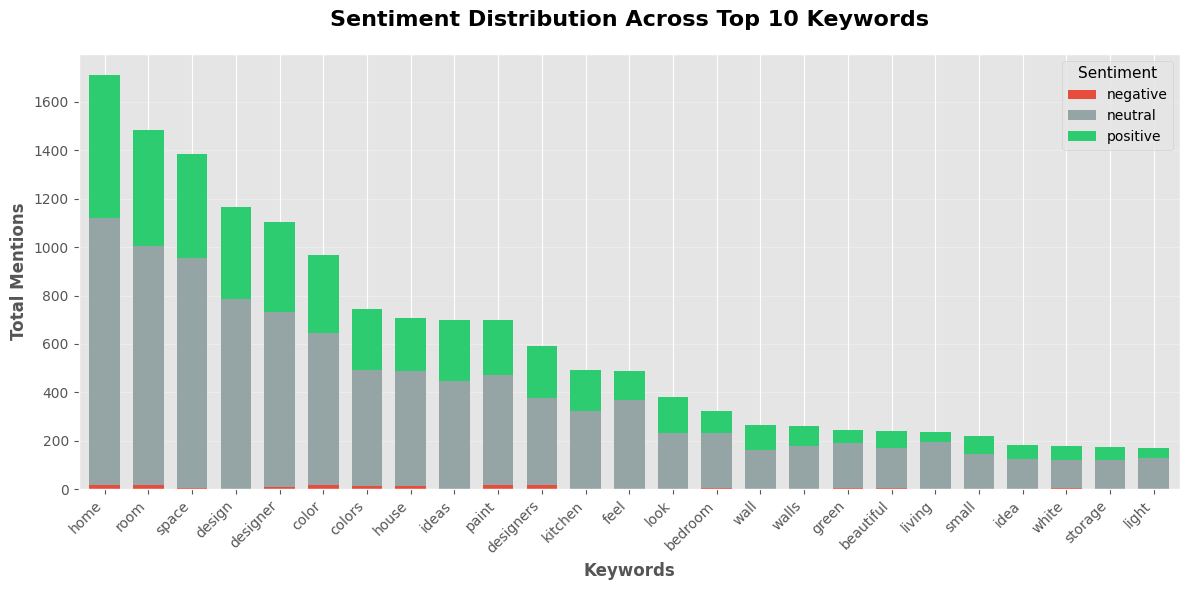

In [38]:
# Step 3: Create the stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))

# Define colors for each sentiment
colors = {
    'negative': '#e74c3c',   # Red
    'neutral': '#95a5a6',    # Gray
    'positive': '#2ecc71'    # Green
}

# Create the stacked bar chart
pivot_data.plot(kind='bar', 
                stacked=True, 
                ax=ax,
                color=[colors[col] for col in pivot_data.columns],
                width=0.7)

# Customize the chart
ax.set_title('Sentiment Distribution Across Top 10 Keywords', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Keywords', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Mentions', fontsize=12, fontweight='bold')
ax.legend(title='Sentiment', title_fontsize=11, fontsize=10)
ax.set_xticklabels(pivot_data.index, rotation=45, ha='right')

# Add grid for better readability
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation

Total mentions for a keyword are represented by the height of each bar. The segment colors (green = positive, gray = neutral, red = negative) are the proportions of each sentiment category. Keywords with more green indicate positive associations, while those with more red suggest negative coverage. However, keywords dominated in gray are mentioned in neutral contexts.

In practice, a client might use this chart to determine what topics to write most about on social media or in a decision for an upcoming product order.

### Visualizing Entity Sentiment by Overall Total Mentions

This approach examines sentiment distribution across the most frequently mentioned keywords. The words most used amongst all blog website articles are shown with thehir positive and negative sentiment ratios within a bar chart.


#### Data Preparation

Both visualizations reuse the same base aggregation (`entity_sentiment`) to avoid duplication. The differences are:
1. **First chart**: Top 15 entities by total mention volume
2. **Second chart**: Top 10 entities ordered by negative sentiment (below)

In [39]:
# Aggregate data by entity and sentiment (reused across all entity visualizations)
entity_sentiment = df.groupby(['ENTITY_TEXT', 'SENTIMENT'])['MENTIONS'].sum().reset_index()

# Visualization 1: Top 15 entities by total mentions
top_entities_by_volume = df.groupby('ENTITY_TEXT')['MENTIONS'].sum().nlargest(25).index.tolist()
entity_sentiment_top_volume = entity_sentiment[entity_sentiment['ENTITY_TEXT'].isin(top_entities_by_volume)]

print(f"Top 15 entities by total mentions: {top_entities_by_volume}")
print(f"\nAggregated data shape: {entity_sentiment_top_volume.shape}")
entity_sentiment_top_volume.head(10)

Top 15 entities by total mentions: ['House', 'Benjamin Moore', 'ED', 'ER', 'THE ENTIRE HOUSE', 'Limewash', 'Sherwin-Williams', 'Brown', 'Whole Home', 'Farrow & Ball', 'Meghan Shouse', 'The Home Depot', 'French', 'Hayslett', 'Instagram', 'Naiman', 'New York', 'Kate McGregor', 'Davis', 'Limewash paint', 'Roman', 'Color of the Year', 'Home Services', 'Mauve', 'McEvoy']

Aggregated data shape: (38, 3)


,ENTITY_TEXT,SENTIMENT,MENTIONS
67,Benjamin Moore,neutral,467
68,Benjamin Moore,positive,405
101,Brown,neutral,300
153,Color of the Year,neutral,165
182,Davis,neutral,150
183,Davis,positive,30
199,ED,neutral,570
202,ER,neutral,540
224,Farrow & Ball,neutral,225
225,Farrow & Ball,positive,30


**Pivoting the data for stacking**

In [40]:
# Pivot the data so sentiments become columns
pivot_entity_volume = entity_sentiment_top_volume.pivot(index='ENTITY_TEXT', 
                                                         columns='SENTIMENT', 
                                                         values='MENTIONS').fillna(0)

# Reorder columns to control the stack order
pivot_entity_volume = pivot_entity_volume.reindex(columns=sentiment_order, fill_value=0)

# Sort by total mentions (descending)
pivot_entity_volume['total'] = pivot_entity_volume.sum(axis=1)
pivot_entity_volume = pivot_entity_volume.sort_values('total', ascending=False).drop('total', axis=1)

print("Pivoted entity data (by volume):")
pivot_entity_volume

Pivoted entity data (by volume):


SENTIMENT,negative,neutral,positive
ENTITY_TEXT,,,
House,0.0,1755.0,840.0
Benjamin Moore,0.0,467.0,405.0
ED,0.0,570.0,0.0
ER,0.0,540.0,0.0
THE ENTIRE HOUSE,0.0,435.0,0.0
Sherwin-Williams,0.0,255.0,105.0
Limewash,0.0,360.0,0.0
Brown,0.0,300.0,0.0
Whole Home,0.0,180.0,120.0


#### Visualization

**Creating the stacked bar chart for entities**

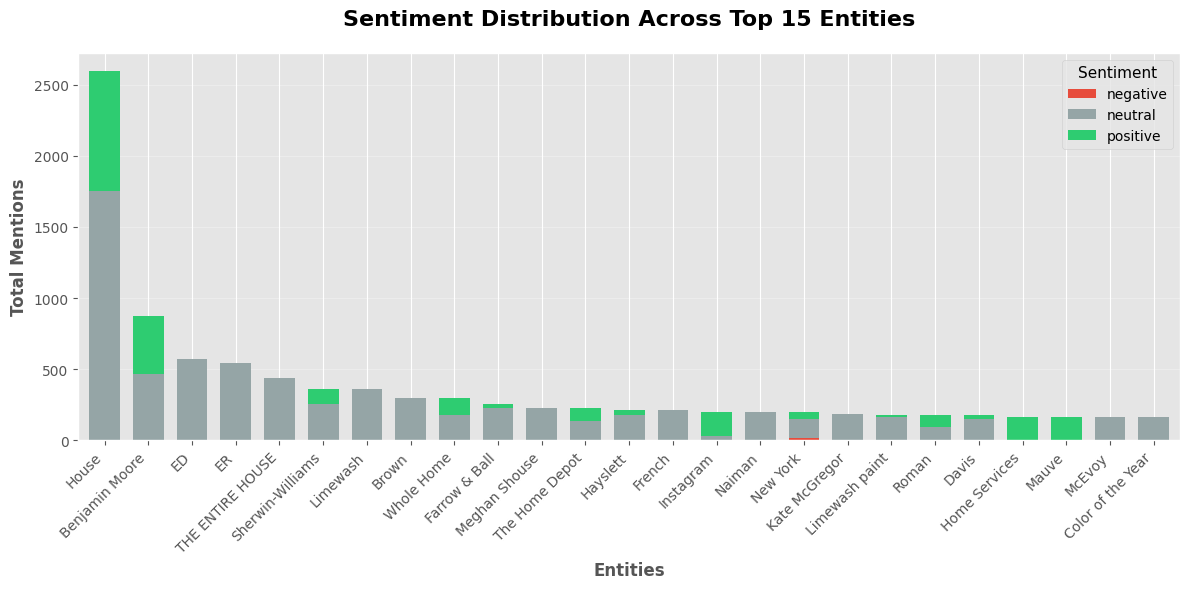

In [41]:
# Reusable visualization function parameters
fig, ax = plt.subplots(figsize=(12, 6))

pivot_entity_volume.plot(kind='bar', 
                          stacked=True, 
                          ax=ax,
                          color=[colors[col] for col in pivot_entity_volume.columns],
                          width=0.7)

# Customize the chart
ax.set_title('Sentiment Distribution Across Top 15 Entities', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Entities', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Mentions', fontsize=12, fontweight='bold')
ax.legend(title='Sentiment', title_fontsize=11, fontsize=10)
ax.set_xticklabels(pivot_entity_volume.index, rotation=45, ha='right')

# Add grid for better readability
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

#### Observation

This chart shows sentiment distribution for named entities such as people, organizations, brands and locations, mentioned in the blog articles. It can be used to understand what entities drive certain topics.

However, a clear observation about this chart is that there is no "negative" sentiment accross any of the top 10 entities. (Except for New York, which is an outlier)

There could be a couple reasons behind this, but the most obvious one is that the most talked about keywords <u>would never</u> include negative sentiment, or else it wouldn't have shown up on the top 10 in the first place.

Instead of pulling the top 10 directly, for entities, we should include a condition to pull in the top 10 entities with a <i>with a negative or positive sentiment</i> attached to it and order by NEGATIVE sentiment.

This way, we can see what top entities have the highest negative sentiment and discover the most mentioned entity with both postitive and negative sentiment.

Another analysis...

### Identifying Entities with Positive or Negative Sentiment, Ordered by Negative Sentiment

This approach focuses on entities with strong sentiment signals (positive or negative), excluding purely neutral entities, and orders them by negative sentiment to highlight problematic entities first. A client might use this graph to understand what brands or keywords to avoid in future business decisions.

#### Data Preparation

In [42]:
entity_sentiment = df.groupby(['ENTITY_TEXT', 'SENTIMENT'])['MENTIONS'].sum().reset_index()

# find entities that have positive OR negative sentiment (not just neutral)
entity_sentiment_set = df.groupby('ENTITY_TEXT')['SENTIMENT'].apply(lambda x: set(x)) 
                                                            # convert each groups sentiment values to a Python set (removing duplicates)

# filter to entities that have 'positive' or 'negative' in their sentiment set
entities_with_sentiment = entity_sentiment_set[
    entity_sentiment_set.apply(lambda x: 'positive' in x or 'negative' in x) 
].index.tolist() # convert to list

print(f"Found {len(entities_with_sentiment)} entities with positive or negative sentiment")

Found 290 entities with positive or negative sentiment


In the previous code, the data was grouped by `ENTITY_TEXT` and `SENTIMENT` and `.apply(lamdba x: set(x))` converts the sentiment valus to a Python set.

The below cell creates a `netagtive_mentions` variable which will be used to count the mentions for the new graph. 

In [43]:
# Get negative mention counts for these entities
negative_mentions = df[
    (df['ENTITY_TEXT'].isin(entities_with_sentiment)) & 
    (df['SENTIMENT'] == 'negative')
].groupby('ENTITY_TEXT')['MENTIONS'].sum()

Then, most important for this graph, entires with <b>negative</b> OR <b>positive</b> sentiment exists are saved into a variable.

In [44]:
# Find entities that have positive OR negative sentiment (not just neutral)
entity_sentiment_set = df.groupby('ENTITY_TEXT')['SENTIMENT'].apply(lambda x: set(x.unique()))

# Filter to entities that have 'positive' or 'negative' in their sentiment set
entities_with_sentiment = entity_sentiment_set[
    entity_sentiment_set.apply(lambda x: 'positive' in x or 'negative' in x)
].index.tolist()

print(f"Found {len(entities_with_sentiment)} entities with positive or negative sentiment")

Found 290 entities with positive or negative sentiment


Now sorting by negative sentiment in decending order should show the top 10 negatively mentioned entities.

In [45]:
# sort by negative mentions (descending) and get top 10
all_sentiment_entities = pd.Series(0, index=entities_with_sentiment)
all_sentiment_entities.update(negative_mentions)
top_entities_by_negative = all_sentiment_entities.nlargest(25).index.tolist()

# filter to only include selected entities
entity_sentiment_top_negative = entity_sentiment[entity_sentiment['ENTITY_TEXT'].isin(top_entities_by_negative)]

print(f"\nTop 10 entities (ordered by negative sentiment):")
for i, entity in enumerate(top_entities_by_negative, 1):
    neg_count = all_sentiment_entities[entity]
    print(f"  {i}. {entity}: {int(neg_count)} negative mentions")

print(f"\nAggregated data shape: {entity_sentiment_top_negative.shape}")
print(f"\nSentiment breakdown for selected entities:")


Top 10 entities (ordered by negative sentiment):
  1. Boozer: 60 negative mentions
  2. Scott: 45 negative mentions
  3. Kikuchi: 30 negative mentions
  4. Song: 30 negative mentions
  5. Dafna Kikuchi: 15 negative mentions
  6. Hamptons: 15 negative mentions
  7. Joanna Saltz: 15 negative mentions
  8. Lindsey Herod: 15 negative mentions
  9. Nate Berkus: 15 negative mentions
  10. New York: 15 negative mentions
  11. Rayman Boozer: 15 negative mentions
  12. Sasha Bikoff: 15 negative mentions
  13. Victorian: 15 negative mentions
  14. ADA: 0 negative mentions
  15. Agárdy: 0 negative mentions
  16. Akbary: 0 negative mentions
  17. Alexander Design: 0 negative mentions
  18. Alexander Reid: 0 negative mentions
  19. Alexandra Gater: 0 negative mentions
  20. Alexandra Kaehler: 0 negative mentions
  21. Alexandra Loew: 0 negative mentions
  22. Ali Budd: 0 negative mentions
  23. Ali Budd's: 0 negative mentions
  24. Allison Willson: 0 negative mentions
  25. Amber Lewis: 0 negative

**Pivot and visualize the data (ordered by negative sentiment):**

In [46]:
# Pivot the data so sentiments become columns (same logic as first viz)
pivot_entity_negative = entity_sentiment_top_negative.pivot(index='ENTITY_TEXT', 
                                                             columns='SENTIMENT', 
                                                             values='MENTIONS').fillna(0)

# Reorder columns to control the stack order
pivot_entity_negative = pivot_entity_negative.reindex(columns=sentiment_order, fill_value=0)

# Sort by NEGATIVE mentions (descending) - key difference from first visualization
pivot_entity_negative = pivot_entity_negative.sort_values('negative', ascending=False)

print("Pivoted entity data (ordered by negative sentiment):")
pivot_entity_negative

Pivoted entity data (ordered by negative sentiment):


SENTIMENT,negative,neutral,positive
ENTITY_TEXT,,,
Boozer,60.0,0.0,0.0
Scott,45.0,30.0,0.0
Song,30.0,60.0,0.0
Kikuchi,30.0,0.0,0.0
Dafna Kikuchi,15.0,0.0,0.0
Sasha Bikoff,15.0,0.0,15.0
Rayman Boozer,15.0,0.0,0.0
New York,15.0,135.0,45.0
Nate Berkus,15.0,30.0,0.0


#### Visualization

In the following graph, because of the new ordering, entities with the highest number of negative mentions should be identified first, and then entities with positive OR negative mentions.

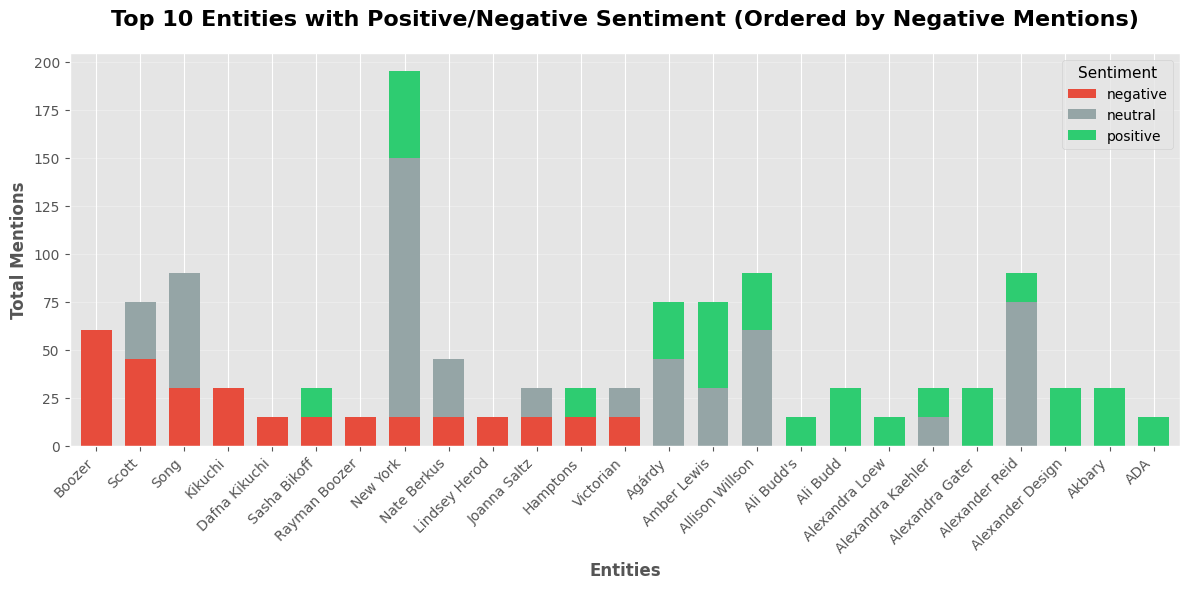


Note: Entities are ordered left-to-right by negative mention count (highest first).


In [47]:
# create stacked bar chart (same visualization logic as first chart)
fig, ax = plt.subplots(figsize=(12, 6))

pivot_entity_negative.plot(kind='bar', 
                            stacked=True, 
                            ax=ax,
                            color=[colors[col] for col in pivot_entity_negative.columns],
                            width=0.7)

# Customize the chart
ax.set_title('Top 10 Entities with Positive/Negative Sentiment (Ordered by Negative Mentions)', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Entities', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Mentions', fontsize=12, fontweight='bold')
ax.legend(title='Sentiment', title_fontsize=11, fontsize=10)
ax.set_xticklabels(pivot_entity_negative.index, rotation=45, ha='right')

# Add grid for better readability
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

print("\nNote: Entities are ordered left-to-right by negative mention count (highest first).")

#### Observation

This graph brings it all together; on the farthest left side should be the entities with the highest (if not 100%) negative seniment, decreasing to the left, where there are entities with more neutral and/or positive sentiment to the right. A client might use this graph to NOT ONLY determine out of all entities, which ones to avoid the most, but also what entities have the highest negative sentiment, while still having the <i>least bit</i> of positive (or neutral) sentiment.

 This prioritization helps e-commerce clients quickly identify high-risk entities while understanding their full sentiment context. An entity with 100 negative mentions and 200 positive mentions tells a different story than one with 100 negative mentions and 0 positive mentions - both are shown here, but ordered by the negative signal strength.

## Visualization 2: Analyzing Confidence Scores for Sentiment

These visualizations will explore the confidence scores of entites in the negative and positive classifications. WigglNet utilizes the sentiment analysis model (RoBERTa) which provides confidence scores indicating how certain it is about the sentiment classification. Examining confidence alongside negative mentions helps distinguish between high and low congfidence entities. High confidence entities represent reliable warning signals, and low confidence entities can be potentially misclassified or ambiguous data.

#### Define Reusable Visualization Functions

Taking a new approach starting this vizualization, all repeating graphing data will be stored in a function to avoid code duplication.

The function `plot_confidence_bar_chart` creates a horizontal bar chart with color gradient based confidence. It takes four arguments: the data, mention counts, confidence scores, sentiment type and colormap for each of the two graphs that will be generated for each top positive and negative entities.

In [48]:
import matplotlib.cm as cm
from matplotlib.colors import Normalize

def plot_confidence_bar_chart(data, mentions_col, confidence_col, 
                                sentiment_type, color_map='Reds'):
    # sort by mentions for better visualization
    data_sorted = data.sort_values(mentions_col, ascending=True)
    
    # create figure object and ax
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # normalize the confidence scores across the data,
    #   so that it can be color mapped
    norm = Normalize(vmin=data_sorted[confidence_col].min(), 
                     vmax=data_sorted[confidence_col].max())
    cmap = cm.get_cmap(color_map) # call in color map
    
    # Create bars with color based on confidence
    ax.barh(range(len(data_sorted)), 
            data_sorted[mentions_col],
            color=cmap(norm(data_sorted[confidence_col])))
    
    # Customize chart
    ax.set_yticks(range(len(data_sorted)))
    ax.set_yticklabels(data_sorted['ENTITY_TEXT'], fontsize=10)
    ax.set_xlabel(f'Total {sentiment_type} Mentions', fontsize=12, fontweight='bold')
    ax.set_ylabel('Entity', fontsize=12, fontweight='bold')
    ax.set_title(f'Top 25 {sentiment_type}ly Mentioned Entities\n(Color Intensity = Confidence Level)', 
                 fontsize=14, fontweight='bold', pad=20)
    
    # Add grid
    ax.xaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)
    
    # Add colorbar
    sm = cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label('Average Confidence Score', fontsize=11, fontweight='bold')
    
    # Add value labels on bars
    for i, (mentions, confidence) in enumerate(zip(data_sorted[mentions_col], 
                                                     data_sorted[confidence_col])):
        ax.text(mentions + 1, i, f'{int(mentions)} ({confidence:.2f})', 
                va='center', fontsize=8, color='black')
    
    plt.tight_layout()
    plt.show()

This function, `plot_confidence_scatter` creates a scatter plot of confidence compared with mentions with quadrant analysis. The arguments are mostly the same as the bar graph, but high and low quadrant args are added and max_mentions for a total.

In [49]:
def plot_confidence_scatter(data, mentions_col, confidence_col, 
                             sentiment_type, color_map='Reds', 
                             quadrant_color_high='#ffcccc', quadrant_color_low='#ffffcc',
                             max_mentions=None):
    # Create figure
    fig, ax = plt.subplots(figsize=(14, 8))
    
    # Plot scatter points
    scatter = ax.scatter(data[mentions_col], 
                         data[confidence_col],
                         s=200,
                         c=data[confidence_col],
                         cmap=color_map,
                         alpha=0.6,
                         edgecolors='black',
                         linewidth=1.5)
    
    # Add entity labels
    for idx, row in data.iterrows():
        ax.annotate(row['ENTITY_TEXT'], 
                    (row[mentions_col], row[confidence_col]),
                    fontsize=9,
                    xytext=(5, 5),
                    textcoords='offset points',
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))
    
    # Add quadrant lines (median splits)
    median_mentions = data[mentions_col].median()
    median_confidence = data[confidence_col].median()
    
    ax.axvline(median_mentions, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    ax.axhline(median_confidence, color='gray', linestyle='--', alpha=0.5, linewidth=1)
    
    # Add quadrant labels
    ax.text(median_mentions * 1.5, data[confidence_col].max() * 0.98, 
            'High Confidence\nHigh Volume', ha='center', fontsize=10, 
            bbox=dict(boxstyle='round', facecolor=quadrant_color_high, alpha=0.7))
    ax.text(median_mentions * 0.5, data[confidence_col].max() * 0.98, 
            'High Confidence\nLow Volume', ha='center', fontsize=10,
            bbox=dict(boxstyle='round', facecolor=quadrant_color_low, alpha=0.7))
    
    # Customize chart
    ax.set_xlabel(f'Total {sentiment_type} Mentions', fontsize=12, fontweight='bold')
    ax.set_ylabel('Average Confidence Score', fontsize=12, fontweight='bold')
    ax.set_title(f'Confidence vs. {sentiment_type} Mention Count for Top 25 Entities', 
                 fontsize=14, fontweight='bold', pad=20)
    ax.grid(True, alpha=0.3)
    
    # Cap the x-axis if max_mentions is specified
    if max_mentions is not None:
        ax.set_xlim(0, max_mentions)
    
    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('Confidence Score', fontsize=11, fontweight='bold')
    
    plt.tight_layout()
    plt.show()

#### Data Preparation

Filter the existing dataset for negative sentiment and aggregate by entity to calculate total negative mentions and verage confidence score across all negative mentions.

In [50]:
# Filter the existing dataframe for negative and positive sentiment
df_negative = df[df['SENTIMENT'] == 'negative'].copy()
df_positive = df[df['SENTIMENT'] == 'positive'].copy()

print(f"Found {len(df_negative)} negative sentiment records")
print(f"Confidence score range: {df_negative['CONFIDENCE'].min():.3f} to {df_negative['CONFIDENCE'].max():.3f}")
print(f"Average confidence: {df_negative['CONFIDENCE'].mean():.3f}\n")

print(f"Found {len(df_positive)} positive sentiment records")
print(f"Confidence score range: {df_positive['CONFIDENCE'].min():.3f} to {df_positive['CONFIDENCE'].max():.3f}")
print(f"Average confidence: {df_positive['CONFIDENCE'].mean():.3f}\n")

Found 195 negative sentiment records
Confidence score range: 0.519 to 0.825
Average confidence: 0.663

Found 5287 positive sentiment records
Confidence score range: 0.483 to 0.978
Average confidence: 0.774



Sum the mentions and find the mean confidence to put ina variable called `negative_entity_stats`.

In [51]:
# Aggregate NEGATIVE entities: sum mentions and average confidence
negative_entity_stats = df_negative.groupby('ENTITY_TEXT').agg({
    'MENTIONS': 'sum',
    'CONFIDENCE': 'mean'
}).reset_index()

negative_entity_stats.columns = ['ENTITY_TEXT', 'TOTAL_NEGATIVE_MENTIONS', 'AVG_CONFIDENCE']
top_25_negative = negative_entity_stats.nlargest(25, 'TOTAL_NEGATIVE_MENTIONS')
top_25_negative['AVG_CONFIDENCE'] = top_25_negative['AVG_CONFIDENCE'].round(3)

# Aggregate POSITIVE entities: sum mentions and average confidence
positive_entity_stats = df_positive.groupby('ENTITY_TEXT').agg({
    'MENTIONS': 'sum',
    'CONFIDENCE': 'mean'
}).reset_index()

positive_entity_stats.columns = ['ENTITY_TEXT', 'TOTAL_POSITIVE_MENTIONS', 'AVG_CONFIDENCE']
top_25_positive = positive_entity_stats.nlargest(25, 'TOTAL_POSITIVE_MENTIONS')
top_25_positive['AVG_CONFIDENCE'] = top_25_positive['AVG_CONFIDENCE'].round(3)

Printing the results for top negative and positive mentions

In [52]:
print(f"Top 25 entities by negative mentions:\n")
print(top_25_negative.to_string(index=False))
print(f"\n{'='*70}")
print(f"Confidence statistics for top 25 negative:")
print(f"  Mean: {top_25_negative['AVG_CONFIDENCE'].mean():.3f}")
print(f"  Min:  {top_25_negative['AVG_CONFIDENCE'].min():.3f}")
print(f"  Max:  {top_25_negative['AVG_CONFIDENCE'].max():.3f}")

print(f"\n\nTop 25 entities by positive mentions:\n")
print(top_25_positive.to_string(index=False))
print(f"\n{'='*70}")
print(f"Confidence statistics for top 25 positive:")
print(f"  Mean: {top_25_positive['AVG_CONFIDENCE'].mean():.3f}")
print(f"  Min:  {top_25_positive['AVG_CONFIDENCE'].min():.3f}")
print(f"  Max:  {top_25_positive['AVG_CONFIDENCE'].max():.3f}")

Top 25 entities by negative mentions:

  ENTITY_TEXT  TOTAL_NEGATIVE_MENTIONS  AVG_CONFIDENCE
       Boozer                       60           0.776
        Scott                       45           0.702
      Kikuchi                       30           0.825
         Song                       30           0.751
Dafna Kikuchi                       15           0.825
     Hamptons                       15           0.519
 Joanna Saltz                       15           0.636
Lindsey Herod                       15           0.524
  Nate Berkus                       15           0.636
     New York                       15           0.519
Rayman Boozer                       15           0.636
 Sasha Bikoff                       15           0.636
    Victorian                       15           0.630

Confidence statistics for top 25 negative:
  Mean: 0.663
  Min:  0.519
  Max:  0.825


Top 25 entities by positive mentions:

     ENTITY_TEXT  TOTAL_POSITIVE_MENTIONS  AVG_CONFIDENCE
      

#### Bar Chart with Color Gradient by Confidence

Bar height represents negative mention count, while color intensity shows confidence level. Darker bars indicate higher model confidence in the negative sentiment classification.

/tmp/ipykernel_13687/2958685450.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(color_map) # call in color map


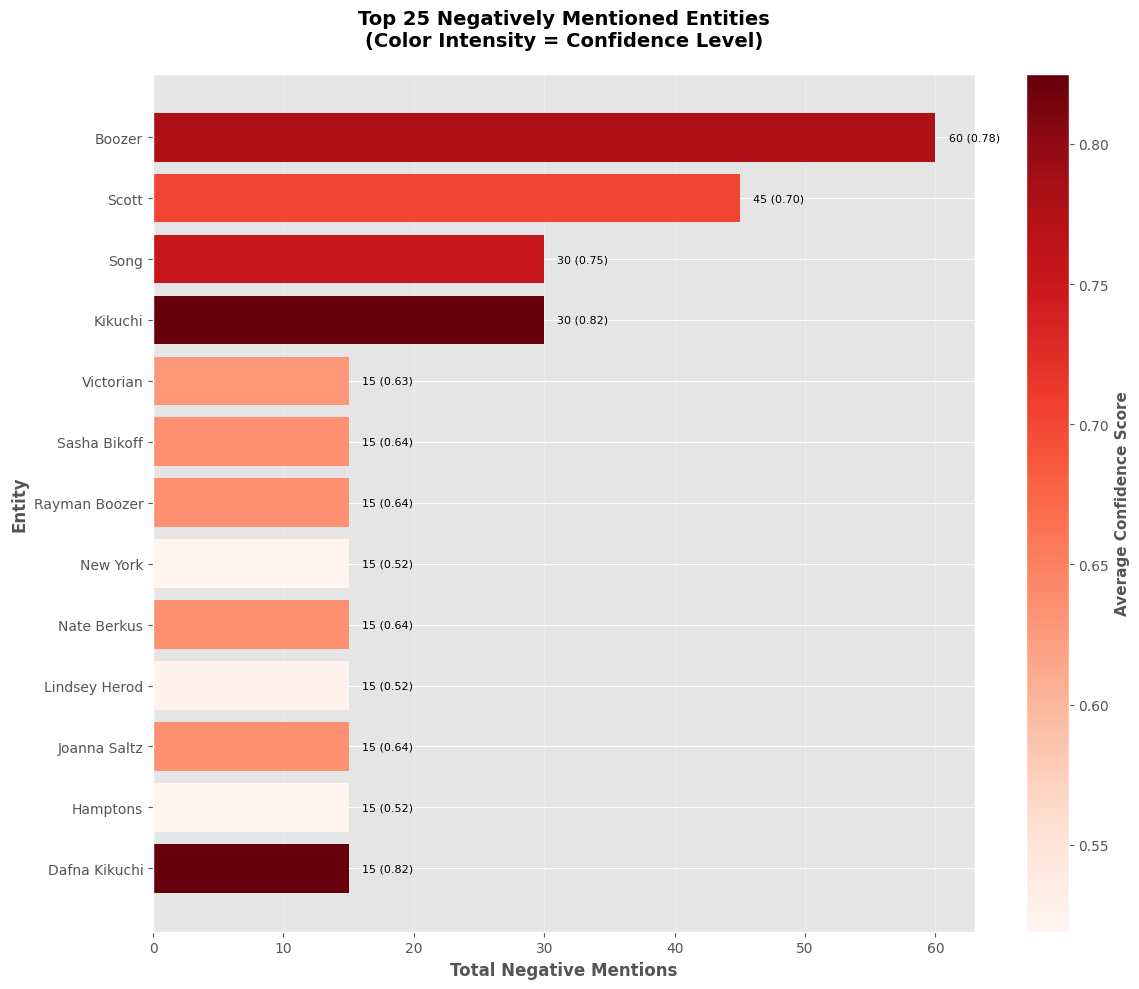

In [53]:
# Use the reusable function for negative entities bar chart
plot_confidence_bar_chart(
    data=top_25_negative,
    mentions_col='TOTAL_NEGATIVE_MENTIONS',
    confidence_col='AVG_CONFIDENCE',
    sentiment_type='Negative',
    color_map='Reds'
)

#### Visualization 2.2: Scatter Plot - Confidence vs. Negative Mentions

This plot helps identify patterns:
- **Top-right quadrant**: High mentions + high confidence = most reliable warning signals
- **Top-left quadrant**: Low mentions + high confidence = emerging concerns
- **Bottom-right quadrant**: High mentions + low confidence = potentially misclassified
- **Bottom-left quadrant**: Low mentions + low confidence = least concern

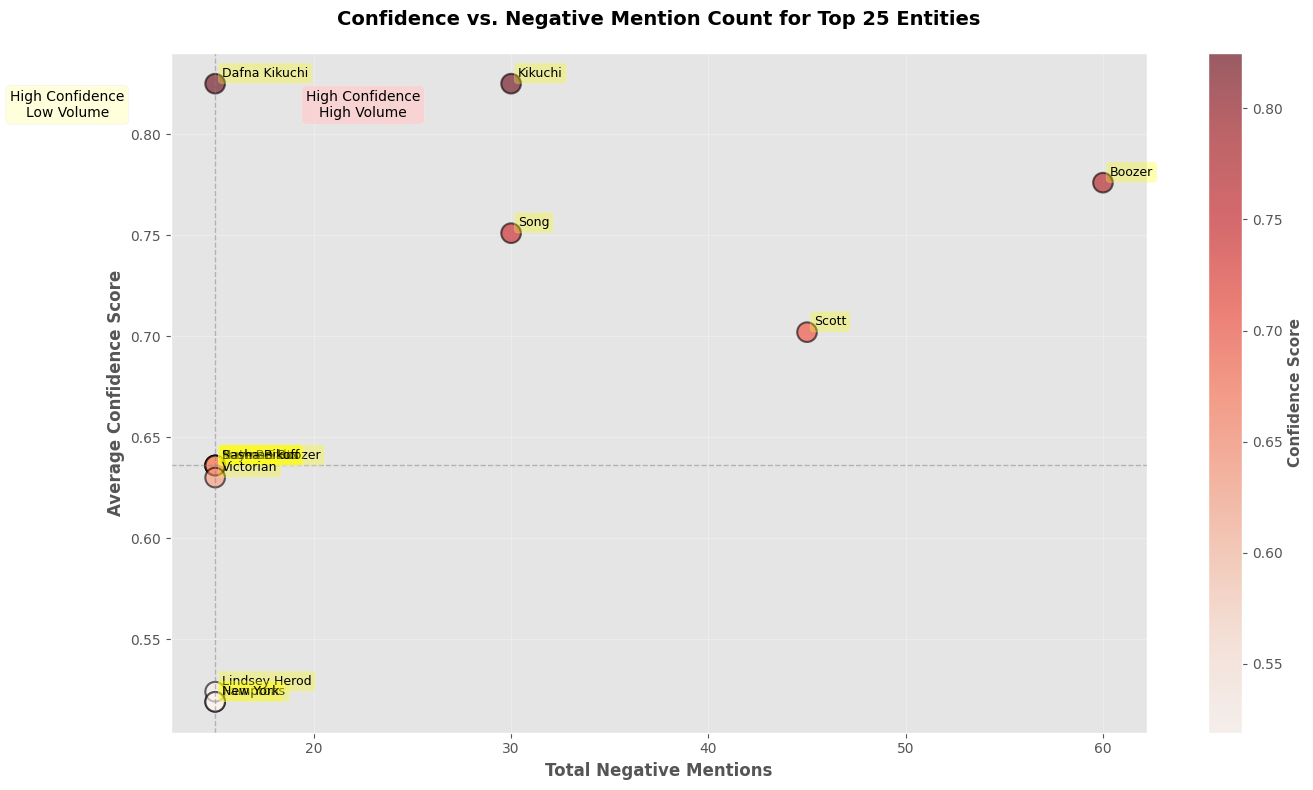

In [54]:
# Use the reusable function for negative entities scatter plot
plot_confidence_scatter(
    data=top_25_negative,
    mentions_col='TOTAL_NEGATIVE_MENTIONS',
    confidence_col='AVG_CONFIDENCE',
    sentiment_type='Negative',
    color_map='Reds',
    quadrant_color_high='#ffcccc',
    quadrant_color_low='#ffffcc'
)

#### Interpreting Confidence Scores

**What Confidence Means:**
- **High confidence (>0.85)**: The RoBERTa model is very certain about the negative sentiment classification
- **Medium confidence (0.70-0.85)**: Moderately certain, typical for clear negative language
- **Low confidence (<0.70)**: Uncertain classification, may indicate ambiguous language or misclassification

**For WigglNet Clients:**

1. **Prioritize high-confidence, high-volume entities** (darker, taller bars in Chart 1; top-right quadrant in Chart 2)
   - These are the most reliable negative signals
   - E-commerce sellers should investigate these entities thoroughly before associating with them

2. **Investigate low-confidence entities** (lighter bars in Chart 1; bottom of Chart 2)
   - May be false negatives due to sarcasm, complex language, or context issues
   - Manual review recommended before making business decisions

3. **Confidence + Volume = Risk Score**
   - High mentions × High confidence = Critical warning (avoid)
   - High mentions × Low confidence = Needs review (investigate)
   - Low mentions × High confidence = Watch list (monitor)
   - Low mentions × Low confidence = Low priority

This two-dimensional analysis helps clients distinguish between solid negative signals and potentially uncertain classifications, leading to better-informed business decisions.

### Positive Sentiment Confidence Analysis

Now analyzing the top 25 positively mentioned entities with their confidence scores to identify reliable positive signals.

#### Visualization 3: Bar Chart with Color Gradient by Confidence (Positive Entities)

Bar height represents positive mention count, while color intensity shows confidence level. Darker bars indicate higher model confidence in the positive sentiment classification.

/tmp/ipykernel_13687/2958685450.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap(color_map) # call in color map


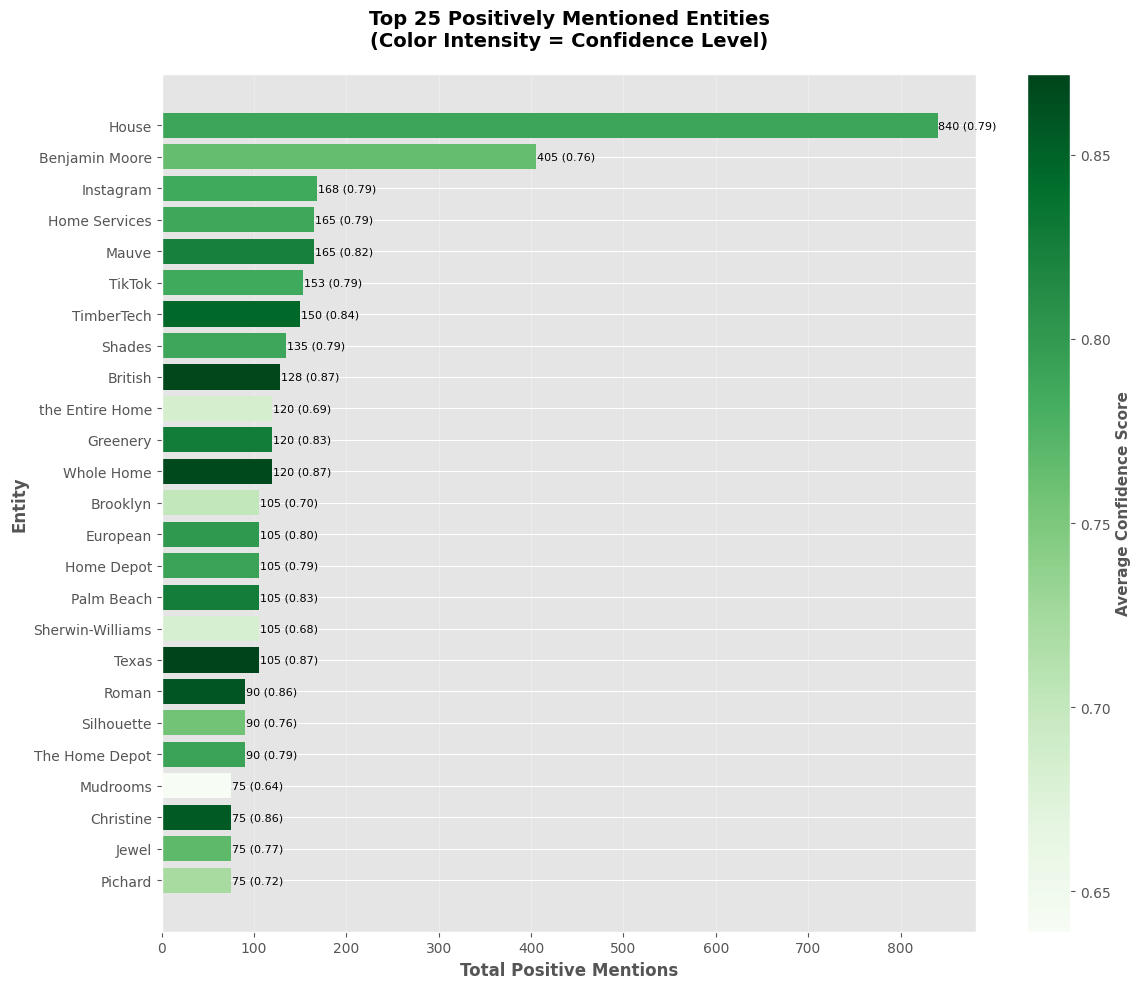

In [55]:
# Use the reusable function for positive entities bar chart
plot_confidence_bar_chart(
    data=top_25_positive,
    mentions_col='TOTAL_POSITIVE_MENTIONS',
    confidence_col='AVG_CONFIDENCE',
    sentiment_type='Positive',
    color_map='Greens'
)

#### Visualization 4: Scatter Plot - Confidence vs. Positive Mentions

This plot helps identify patterns in positive sentiment:
- **Top-right quadrant**: High mentions + high confidence = most reliable positive signals
- **Top-left quadrant**: Low mentions + high confidence = emerging positive trends
- **Bottom-right quadrant**: High mentions + low confidence = potentially uncertain classifications
- **Bottom-left quadrant**: Low mentions + low confidence = least significant

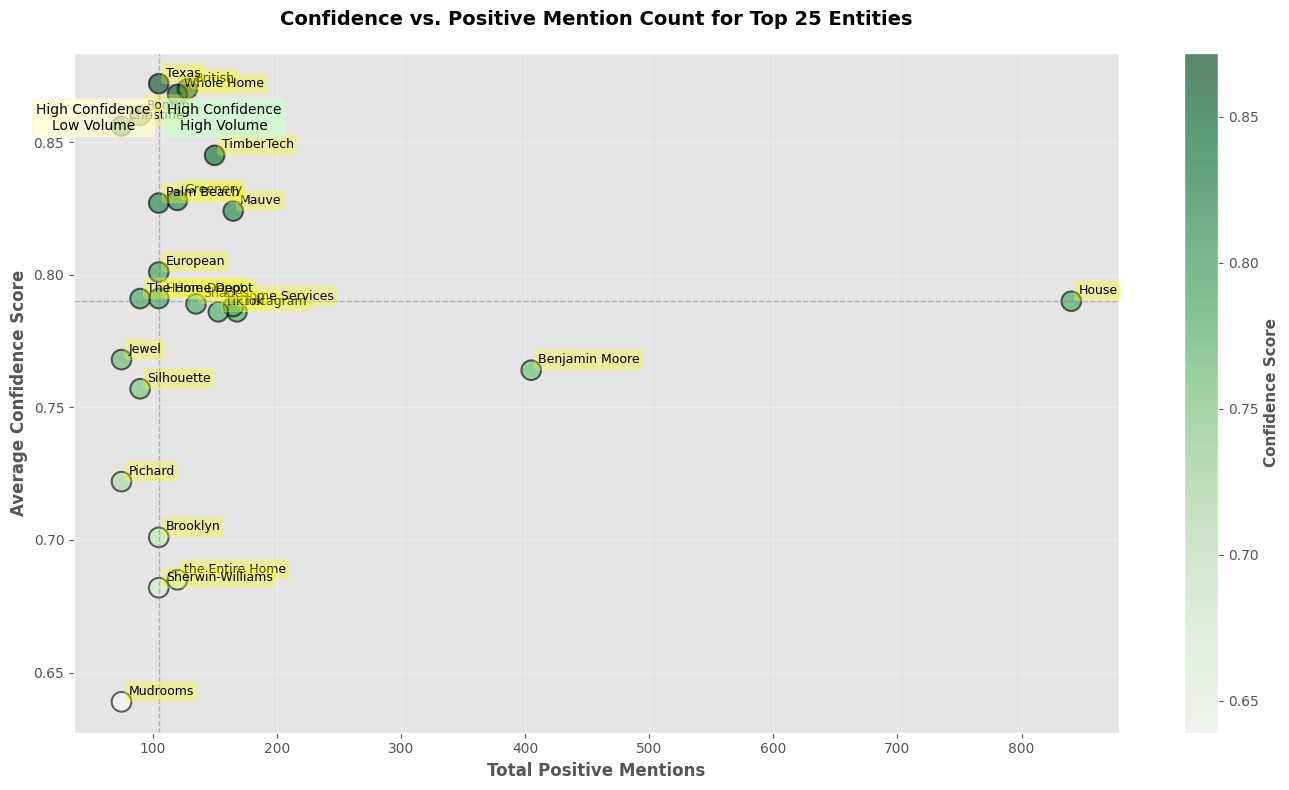

In [56]:
# Use the reusable function for positive entities scatter plot
plot_confidence_scatter(
    data=top_25_positive,
    mentions_col='TOTAL_POSITIVE_MENTIONS',
    confidence_col='AVG_CONFIDENCE',
    sentiment_type='Positive',
    color_map='Greens',
    quadrant_color_high='#ccffcc',
    quadrant_color_low='#ffffcc'
)

#### Interpreting Positive Confidence Scores

**For WigglNet Clients:**

1. **Prioritize high-confidence, high-volume positive entities** (darker, taller bars in Chart 3; top-right quadrant in Chart 4)
   - These are the most reliable positive signals
   - E-commerce sellers should consider partnering with or promoting these entities
   - Strong candidates for marketing and product development

2. **Investigate low-confidence positive entities** (lighter bars in Chart 3; bottom of Chart 4)
   - May require manual review to verify genuine positive sentiment
   - Could indicate mixed messaging or context-dependent positivity

3. **Positive Confidence + Volume = Opportunity Score**
   - High mentions × High confidence = Prime opportunity (promote/partner)
   - High mentions × Low confidence = Needs review (investigate further)
   - Low mentions × High confidence = Emerging trend (monitor closely)
   - Low mentions × Low confidence = Low priority

**Comparing Positive vs. Negative:**
By analyzing both positive and negative entities with confidence scores, WigglNet clients can make balanced decisions:
- Entities appearing in both lists may have polarizing reputations
- Pure positive entities (high confidence) are safe bets for partnerships
- Entities with high positive mentions but low confidence may need deeper investigation before committing